# Amazon 游戏商品数据：探索性分析

数据为 Amazon Review Data (2018) 的 Video_Games 品类，包含评论表与商品元数据表。本 notebook 对应 P1 阶段，目标是把解析后的 parquet 读一遍，确认评分、品类、共购篮、价格、文本长度与缺失情况的整体形态，为后续关联规则、分类与聚类定参数。

运行前先在项目根目录执行 `python src/parse.py`，生成 `data/processed/reviews.parquet` 与 `meta.parquet`。

## 环境与口径

- 解释器使用 conda 环境 `amazon-games`，依赖版本见 `requirements.txt`。
- 商品表已按 `asin` 去重，评论表保留全部 2,565,349 条。
- 图中金额单位为美元，文本长度单位为字符。
- 图片统一保存到 `results/figures/`，文件名与报告图号对应。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "data/processed/reviews.parquet").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("找不到 data/processed/reviews.parquet，请先执行 python src/parse.py")

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


def savefig(fig, name: str) -> None:
    path = FIG_DIR / name
    fig.savefig(path, dpi=180, bbox_inches="tight")
    print("已保存", path.name)


print("项目根目录:", ROOT)

项目根目录: .


In [2]:
REVIEWS = pq.read_table(ROOT / "data/processed/reviews.parquet").to_pandas()
META = pq.read_table(ROOT / "data/processed/meta.parquet").to_pandas()

print("评论表", REVIEWS.shape)
print("商品表", META.shape)
REVIEWS.head(3)

评论表 (2565349, 12)
商品表 (71911, 19)


,reviewerID,asin,reviewerName,overall,verified,reviewTime,unixReviewTime,reviewText,summary,style,vote,image_count
0,A21ROB4YDOZA5P,0439381673,Mary M. Clark,1.0,True,"06 9, 2014",1402272000,I used to play this game years ago and loved i...,Did not like this,NaN,NaN,0
1,A3TNZ2Q5E7HTHD,0439381673,Sarabatya,3.0,True,"05 10, 2014",1399680000,The game itself worked great but the story lin...,Almost Perfect,NaN,NaN,0
2,A1OKRM3QFEATQO,0439381673,Amazon Customer,4.0,True,"02 7, 2014",1391731200,I had to learn the hard way after ordering thi...,DOES NOT WORK WITH MAC OS unless it is 10.3 or...,NaN,15.0,0


## 一、评分分布与类别平衡

评分是分类任务的标签来源。先看原始五档分布，再按 4 星阈值合并成正负两类。这一步只统计标签，不做任何变换，避免后续划分训练集时泄漏。

已保存 fig01_rating_distribution.png


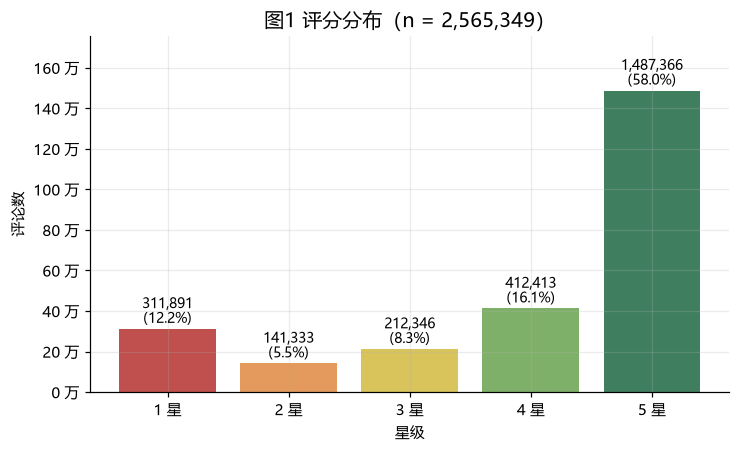

In [3]:
rating_counts = REVIEWS["overall"].value_counts().sort_index()
rating_share = rating_counts / rating_counts.sum()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
colors = ["#c0504d", "#e39a5c", "#d9c45c", "#7fb069", "#3f7f5f"]
bars = ax.bar([f"{int(r)} 星" for r in rating_counts.index], rating_counts.values, color=colors)
for bar, count, share in zip(bars, rating_counts.values, rating_share.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 12000,
        f"{count:,}\n({share:.1%})",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax.set_title("图1 评分分布（n = 2,565,349）", fontsize=13)
ax.set_xlabel("星级")
ax.set_ylabel("评论数")
ax.set_ylim(0, rating_counts.max() * 1.18)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e4:.0f} 万"))
savefig(fig, "fig01_rating_distribution.png")
plt.show()

评分呈明显的 J 形：5 星占 58.0%，4 星及以上合计 74.1%，1 星还有 12.2% 的第二峰。说明买家倾向给高分，但不满意的评价同样集中，不是简单的中庸分布。

对分类任务的含义：正负比约 2.85:1，属于中度不平衡。后续用分层 5 折保持比例，评估以宏 F1 与 PR-AUC 为主，准确率只能作参考。

已保存 fig02_class_balance.png


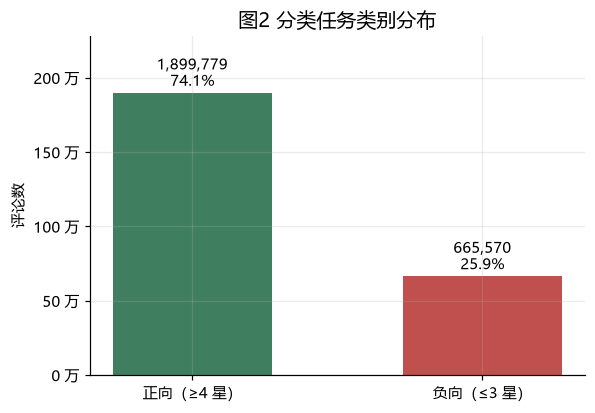

正负比 2.85 : 1


In [4]:
positive = int((REVIEWS["overall"] >= 4).sum())
negative = int((REVIEWS["overall"] < 4).sum())

fig, ax = plt.subplots(figsize=(5.8, 4.0))
bars = ax.bar(
    ["正向（≥4 星）", "负向（≤3 星）"],
    [positive, negative],
    color=["#3f7f5f", "#c0504d"],
    width=0.55,
)
for bar, count in zip(bars, [positive, negative]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20000,
        f"{count:,}\n{count / (positive + negative):.1%}",
        ha="center",
        va="bottom",
    )

ax.set_title("图2 分类任务类别分布", fontsize=13)
ax.set_ylabel("评论数")
ax.set_ylim(0, max(positive, negative) * 1.2)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e4:.0f} 万"))
savefig(fig, "fig02_class_balance.png")
plt.show()

print(f"正负比 {positive / negative:.2f} : 1")

## 二、评论量的时间趋势

时间戳统一用 `unixReviewTime`，`reviewTime` 的字符串格式不统一，不作为分析字段。时间范围从 1997-11 到 2018-10。

已保存 fig03_reviews_over_time.png


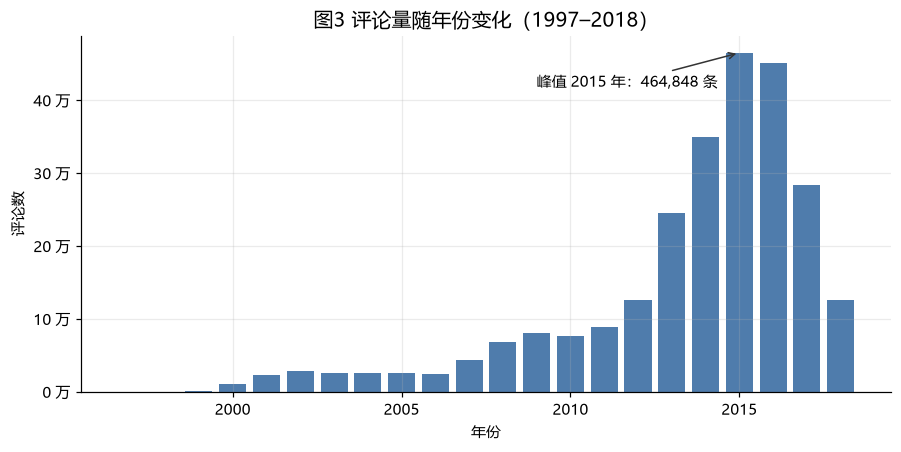

unixReviewTime
2013    244725
2014    348814
2015    464848
2016    451521
2017    283319
2018    126159


In [5]:
years = pd.to_datetime(REVIEWS["unixReviewTime"], unit="s").dt.year
by_year = years.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.bar(by_year.index, by_year.values, color="#4f7cac")
peak_year = int(by_year.idxmax())
ax.annotate(
    f"峰值 {peak_year} 年：{by_year.max():,} 条",
    xy=(peak_year, by_year.max()),
    xytext=(peak_year - 6, by_year.max() * 0.9),
    arrowprops=dict(arrowstyle="->", color="#333333"),
)
ax.set_title("图3 评论量随年份变化（1997–2018）", fontsize=13)
ax.set_xlabel("年份")
ax.set_ylabel("评论数")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e4:.0f} 万"))
savefig(fig, "fig03_reviews_over_time.png")
plt.show()

print(by_year.tail(6).to_string())

评论量在 2013 年后快速上升，2015 年达到峰值 46.5 万条，之后回落。2018 年只覆盖到 10 月 2 日，所以最后一根柱子偏低是截断造成的，不是需求下降。

对建模的含义：若按时间切分训练集与测试集，2015–2016 年的样本会占主导；本项目采用随机分层 5 折，时间只作为特征与漂移分析，不参与划分。

## 三、商品品类结构

商品表按 `asin` 去重后 71,911 件。`main_cat` 有 120 条为空，另有少量 HTML 图片串，统计时归入“缺失/其他”。类目路径 `category` 的首层几乎全是 `Video Games`，真正的差异在第二、三层。

已保存 fig04_main_cat.png


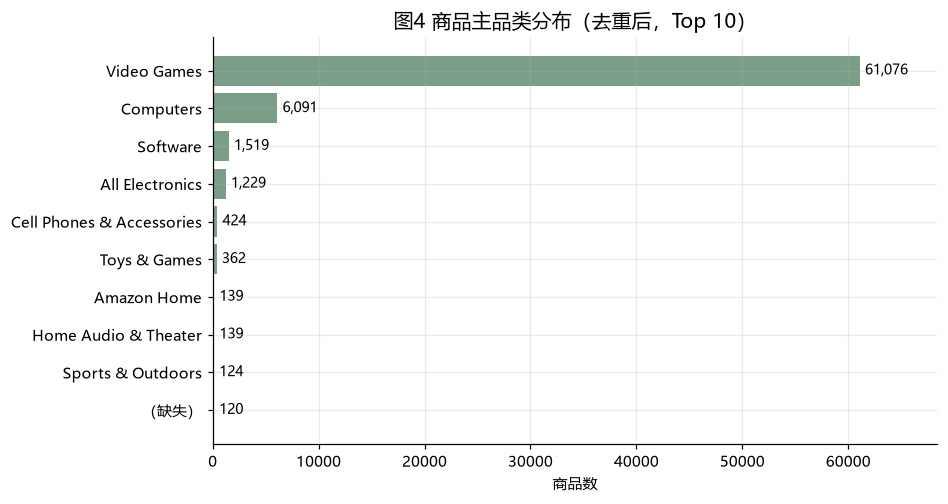

Video Games 占比 84.9%


In [6]:
cat_counts = META["main_cat"].fillna("（缺失）").value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(cat_counts.index, cat_counts.values, color="#7b9e89")
for bar, count in zip(bars, cat_counts.values):
    ax.text(count + 500, bar.get_y() + bar.get_height() / 2, f"{count:,}", va="center", fontsize=9)
ax.set_title("图4 商品主品类分布（去重后，Top 10）", fontsize=13)
ax.set_xlabel("商品数")
ax.set_xlim(0, cat_counts.max() * 1.12)
savefig(fig, "fig04_main_cat.png")
plt.show()

print("Video Games 占比", f"{cat_counts.get('Video Games', 0) / len(META):.1%}")

Video Games 本体 61,076 件，占 85.0%；其余约 15% 是 Computers、Software、Electronics 等周边。做“游戏商品”分析时如果直接用全表，会把手柄、点卡、耳机也算进来，所以品类边界清洗要保留 `Video Games` 下的游戏本体，剔除 Accessories、Consoles 与纯硬件。

`category` 为空列表的商品 2,091 件（2.9%），这些记录无法判断细分品类，聚类时要么单独成组，要么按 `main_cat` 回填。

## 四、共购篮长分布

`also_buy` 是关联规则的唯一真实篮子来源。39.87% 的商品有非空共购列表，其余为空列表，不是缺失值，不能填补。

已保存 fig05_basket_length.png


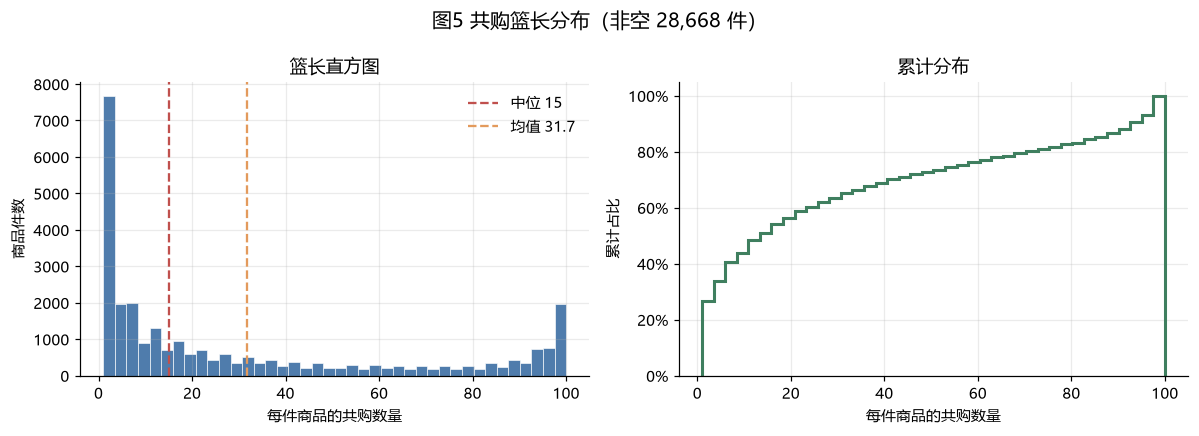

count    28668.00
mean        31.69
std         34.69
min          1.00
50%         15.00
90%         95.00
99%        100.00
max        100.00


In [7]:
basket_len = META["also_buy"].map(len)
non_empty = basket_len[basket_len > 0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
axes[0].hist(non_empty, bins=40, color="#4f7cac", edgecolor="white", linewidth=0.4)
axes[0].axvline(non_empty.median(), color="#c0504d", linestyle="--", label=f"中位 {non_empty.median():.0f}")
axes[0].axvline(non_empty.mean(), color="#e39a5c", linestyle="--", label=f"均值 {non_empty.mean():.1f}")
axes[0].set_title("篮长直方图")
axes[0].set_xlabel("每件商品的共购数量")
axes[0].set_ylabel("商品件数")
axes[0].legend(frameon=False)

axes[1].hist(non_empty, bins=40, cumulative=True, density=True, histtype="step", color="#3f7f5f", linewidth=2)
axes[1].set_title("累计分布")
axes[1].set_xlabel("每件商品的共购数量")
axes[1].set_ylabel("累计占比")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

fig.suptitle("图5 共购篮长分布（非空 28,668 件）", fontsize=13)
fig.tight_layout()
savefig(fig, "fig05_basket_length.png")
plt.show()

print(non_empty.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())

篮长均值 31.7、中位 15、p90 95，长尾一直拖到上限 100。推荐位列表不是收银小票：一次共购 100 件更可能是“买了这个的人还看了”的推荐集合，而不是同一订单。

对关联规则的含义：需要截断篮长，默认上限先用 50；支持度分母用“有篮商品数”而不是全表商品数，否则支持度会被 60% 的空篮稀释。Apriori 与 FP-Growth 的耗时对比也要在这个子集上做。

## 五、价格分布与缺失

`price` 的原始字符串混有 HTML 片段，解析脚本只接受以 `$` 开头后接数字的值，最终可解析 11,908 件（16.56%）。缺失不是随机的，先按品类看缺失率。

已保存 fig06_price_distribution.png


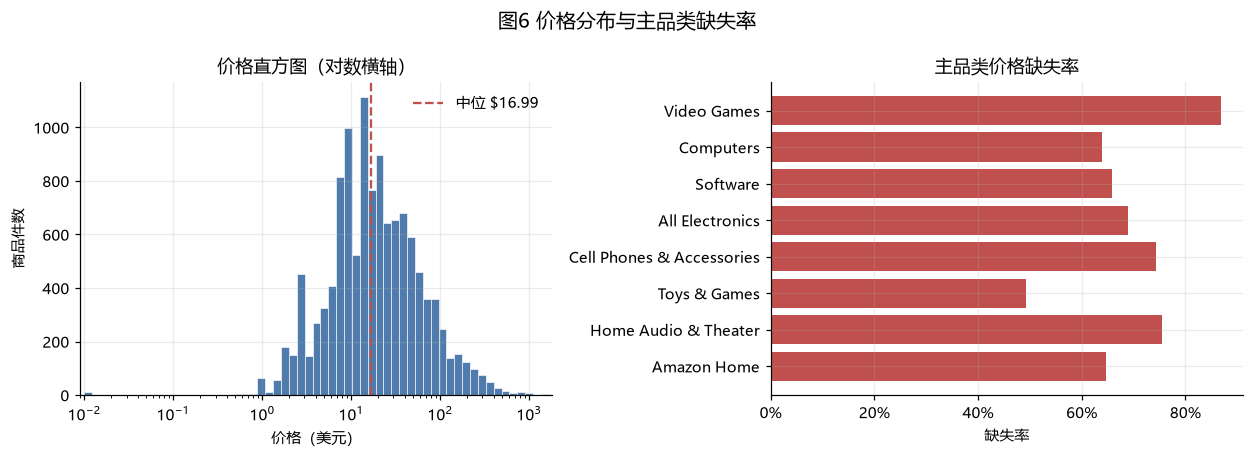

可解析价格 11,908 占比 16.56%
价格为 0 的记录 1
价格分位 {0.25: 8.65, 0.5: 16.99, 0.75: 39.98, 0.9: 83.86, 0.99: 329.94}


In [8]:
prices = META["price"].dropna()
price_positive = prices[prices > 0]
price_bins = np.logspace(np.log10(price_positive.min()), np.log10(price_positive.max()), 60)
top_cats = META["main_cat"].value_counts().head(8).index
miss_by_cat = (
    META[META["main_cat"].isin(top_cats)]
    .groupby("main_cat")["price"]
    .apply(lambda s: s.isna().mean())
    .reindex(top_cats)
)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].hist(price_positive, bins=price_bins, color="#4f7cac", edgecolor="white", linewidth=0.4)
axes[0].set_xscale("log")
axes[0].set_xlim(price_positive.min() * 0.9, price_positive.max() * 1.1)
axes[0].axvline(prices.median(), color="#c0504d", linestyle="--", label=f"中位 ${prices.median():.2f}")
axes[0].set_title("价格直方图（对数横轴）")
axes[0].set_xlabel("价格（美元）")
axes[0].set_ylabel("商品件数")
axes[0].legend(frameon=False)

axes[1].barh(miss_by_cat.index[::-1], miss_by_cat.values[::-1], color="#c0504d")
axes[1].set_title("主品类价格缺失率")
axes[1].set_xlabel("缺失率")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))

fig.suptitle("图6 价格分布与主品类缺失率", fontsize=13)
fig.tight_layout()
savefig(fig, "fig06_price_distribution.png")
plt.show()

print("可解析价格", f"{len(prices):,}", "占比", f"{len(prices) / len(META):.2%}")
print("价格为 0 的记录", int((prices == 0).sum()))
print("价格分位", prices.quantile([0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_dict())

价格中位 16.99 美元，p90 83.86，长尾到 1,672 美元；分布右偏，建模时用对数价格或分箱更稳。

缺失率在品类间差三倍以上：Video Games 约 13%，Toys & Games 约 51%，Computers 约 36%。这不是 MCAR，价格缺失与商品类型强相关。后续填补要按品类分层，并保留 `price_missing` 指示变量；任何用价格做的特征都要在训练折内拟合填补参数，避免泄漏。

## 六、评论正文长度

文本长度决定分类模型的分词与截断策略。`reviewText` 缺失 1,720 条（0.07%），长度分布右偏严重。

已保存 fig07_review_length.png


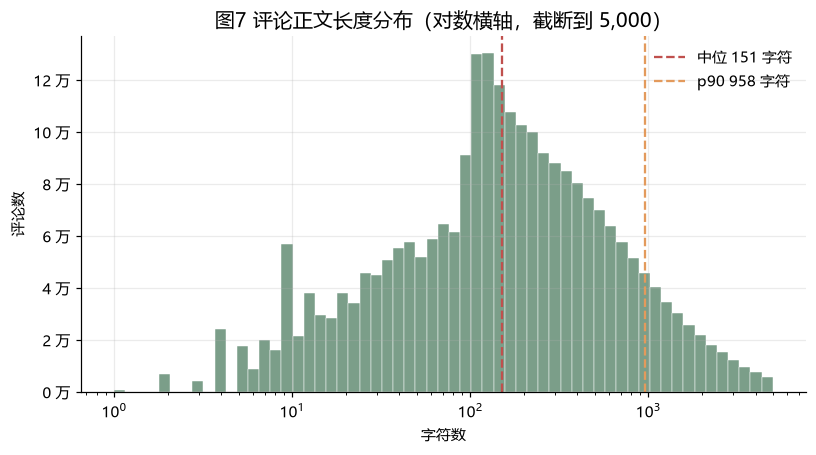

长度分位 {0.25: 55.0, 0.5: 151.0, 0.75: 398.0, 0.9: 958.0, 0.99: 3879.0}
超过 5,000 字符 0.54%


In [9]:
lengths = REVIEWS["reviewText"].str.len().dropna()

length_bins = np.logspace(0, np.log10(5000), 60)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(lengths.clip(lower=1, upper=5000), bins=length_bins, color="#7b9e89", edgecolor="white", linewidth=0.3)
ax.set_xscale("log")
ax.axvline(lengths.median(), color="#c0504d", linestyle="--", label=f"中位 {lengths.median():.0f} 字符")
ax.axvline(lengths.quantile(0.9), color="#e39a5c", linestyle="--", label=f"p90 {lengths.quantile(0.9):.0f} 字符")
ax.set_title("图7 评论正文长度分布（对数横轴，截断到 5,000）", fontsize=13)
ax.set_xlabel("字符数")
ax.set_ylabel("评论数")
ax.legend(frameon=False)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e4:.0f} 万"))
savefig(fig, "fig07_review_length.png")
plt.show()

print("长度分位", lengths.quantile([0.25, 0.5, 0.75, 0.9, 0.99]).round(0).to_dict())
print("超过 5,000 字符", f"{(lengths > 5000).mean():.2%}")

正文中位 151 字符，p90 958，p99 3,879，最长 32,721，说明少数超长评论会拉高计算量。分类时先做轻量清洗（去 HTML、统一空白），词袋或 TF-IDF 限制在 1–2 万维，长文本截断到 2,000 字符即可覆盖九成以上信息。

短评论占比也不低，长度本身可以作为特征，但不能用“评论长度 → 评分”这类事后信息泄漏的构造方式。

## 七、关键字段缺失率

把评论表与商品表放在一起看，区分“真缺失”和“结构缺失”。商品表的 `also_buy`、`category`、`imageURL` 是空列表，不是 null；这里按空列表统计。

已保存 fig08_missing_rates.png


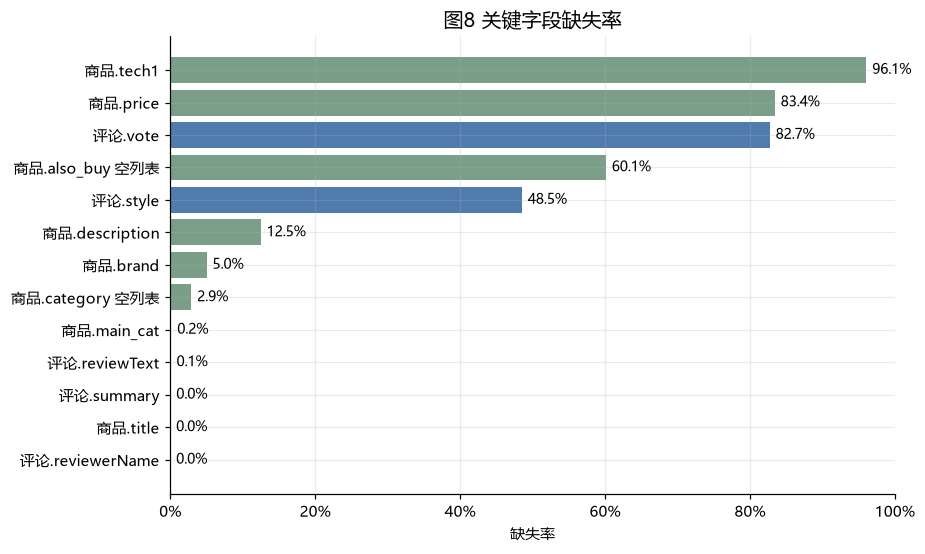

             字段      缺失率
评论.reviewerName 0.000109
       商品.title 0.000111
     评论.summary 0.000320
  评论.reviewText 0.000670
    商品.main_cat 0.001669
商品.category 空列表 0.029078
       商品.brand 0.050298
 商品.description 0.125057
       评论.style 0.485461
商品.also_buy 空列表 0.601341
        评论.vote 0.827425
       商品.price 0.834406
       商品.tech1 0.960715


In [10]:
rows = []
for name in ["reviewerName", "reviewText", "summary", "style", "vote"]:
    rows.append((f"评论.{name}", REVIEWS[name].isna().mean()))
for name in ["title", "brand", "price", "main_cat", "description", "tech1"]:
    rows.append((f"商品.{name}", META[name].isna().mean()))
rows.append(("商品.category 空列表", META["category"].map(len).eq(0).mean()))
rows.append(("商品.also_buy 空列表", META["also_buy"].map(len).eq(0).mean()))

missing = pd.DataFrame(rows, columns=["字段", "缺失率"]).sort_values("缺失率")

fig, ax = plt.subplots(figsize=(8.5, 5.4))
colors = ["#4f7cac" if f.startswith("评论") else "#7b9e89" for f in missing["字段"]]
bars = ax.barh(missing["字段"], missing["缺失率"], color=colors)
for bar, rate in zip(bars, missing["缺失率"]):
    ax.text(rate + 0.008, bar.get_y() + bar.get_height() / 2, f"{rate:.1%}", va="center", fontsize=9)
ax.set_title("图8 关键字段缺失率", fontsize=13)
ax.set_xlabel("缺失率")
ax.set_xlim(0, min(1.0, missing["缺失率"].max() * 1.15))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
savefig(fig, "fig08_missing_rates.png")
plt.show()

print(missing.to_string(index=False))

`vote` 缺失 82.7%，`style` 缺失 48.6%，`price` 缺失 83.4%，三者都不是随机缺失。`vote` 有值的最小值是 2，说明 0 票和 1 票都被记为缺失；这是“没有投票”的结构缺失，不能按均值填补。

## 八、商品评论数的长尾

评论在商品间的分布决定聚类与分类的样本权重。少数热门商品吃掉大量评论，长尾商品只有个位数评论。

已保存 fig09_reviews_per_product.png


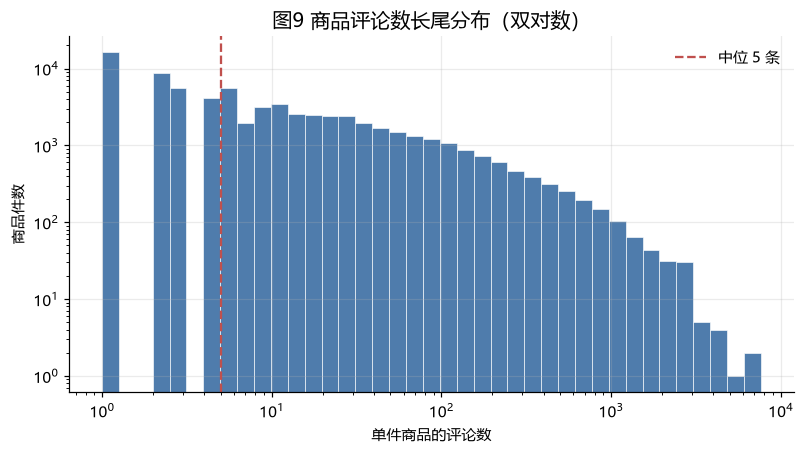

商品数 71982 最大评论数 7630
评论最多的 1% 商品贡献 30.6% 的评论


In [11]:
per_product = REVIEWS["asin"].value_counts()
bins = np.logspace(0, np.log10(per_product.max() + 1), 40)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(per_product, bins=bins, color="#4f7cac", edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
ax.set_yscale("log")
ax.axvline(per_product.median(), color="#c0504d", linestyle="--", label=f"中位 {per_product.median():.0f} 条")
ax.set_title("图9 商品评论数长尾分布（双对数）", fontsize=13)
ax.set_xlabel("单件商品的评论数")
ax.set_ylabel("商品件数")
ax.legend(frameon=False)
savefig(fig, "fig09_reviews_per_product.png")
plt.show()

top_share = per_product.nlargest(max(1, int(len(per_product) * 0.01))).sum() / per_product.sum()
print("商品数", len(per_product), "最大评论数", int(per_product.max()))
print("评论最多的 1% 商品贡献", f"{top_share:.1%}", "的评论")

评论数中位约 13 条，最大单商品超过 1 万条。前 1% 的热门商品贡献了相当大比例的评论，做聚合特征或聚类时如果按商品等权，长尾会主导簇的形态；按评论加权则热门商品主导。报告里要明确采用哪一种口径。

分类任务以评论为单位、按 `asin` 分组做 `StratifiedGroupKFold`，可以避免同一商品的评论同时出现在训练折与验证折，减少商品层面的泄漏。

## 九、缺失机制的证据：按评分看 `vote` 与 `style`

如果 `vote` 的缺失与评分无关，各评分档的非空率应当接近。实际并非如此，这为“结构性缺失”的判断提供了直接证据。

已保存 fig10_vote_style_by_rating.png


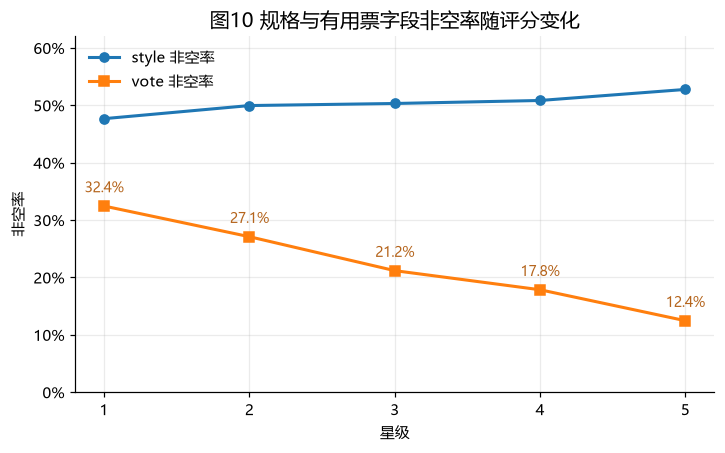

         style_rate  vote_rate
overall                       
1.0           0.476      0.324
2.0           0.499      0.271
3.0           0.503      0.212
4.0           0.508      0.178
5.0           0.527      0.124


In [12]:
by_rating = REVIEWS.groupby("overall").agg(
    style_rate=("style", lambda s: s.notna().mean()),
    vote_rate=("vote", lambda s: s.notna().mean()),
)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(by_rating.index, by_rating["style_rate"], marker="o", linewidth=2, label="style 非空率")
ax.plot(by_rating.index, by_rating["vote_rate"], marker="s", linewidth=2, label="vote 非空率")
for x, y in zip(by_rating.index, by_rating["vote_rate"]):
    ax.annotate(
        f"{y:.1%}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9,
        color="#b5651d",
    )
ax.set_title("图10 规格与有用票字段非空率随评分变化", fontsize=13)
ax.set_xlabel("星级")
ax.set_ylabel("非空率")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_ylim(0, 0.62)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(frameon=False)
savefig(fig, "fig10_vote_style_by_rating.png")
plt.show()

print(by_rating.round(3).to_string())

`vote` 非空率从 1 星的 32.4% 单调降到 5 星的 12.4%：差评更容易被其他用户点“有用”，好评很少有人投票。`style` 则随评分略微上升，在 47.6%–52.7% 之间，差异不大但随时间从 25% 升到 57%。

结论：`vote` 按结构性缺失处理（补 0 并加 `has_vote`），`style` 按年份分层填补并加缺失指示，`price` 按品类分层填补。三种策略分别对应 MNAR、MAR 与 MAR，正好覆盖表 1 要求的“缺失机制判定 + 三种填补策略”。

## 小结与下一步

1. 标签：正向 74.1%，正负比 2.85:1，分类评估以宏 F1 与 PR-AUC 为主。
2. 时间：1997–2018，2015 年峰值 46.5 万条；按 `asin` 分组的分层 5 折避免商品泄漏。
3. 品类：Video Games 占 85%，约 15% 是周边；品类边界清洗要剔除 Accessories、Consoles 与纯硬件。
4. 共购：非空篮 28,668 件，篮长中位 15、上限 100；关联规则先截断到 50，支持度分母用有篮商品数。
5. 价格：仅 16.56% 可解析，缺失与品类强相关，按品类分层填补并保留指示变量。
6. 文本：中位 151 字符，p90 958；分类前做轻量清洗，TF-IDF 控制维度。
7. 缺失：`vote` 结构性缺失、`style` 随年份 MAR、`price` 随品类 MAR，分别对应补 0、分层众数、分层中位数三种策略。

下一步进入 P2：构建评论 × 商品的融合宽表，生成时间窗、文本统计与交互特征，并固定 `StratifiedGroupKFold(groups=asin)` 的划分。